# Klasifikasi Metode Pembayaran dengan Random Forest

Random Forest pada data transaksi yang sama, sekaligus melihat fitur paling berpengaruh.

## 1. Muat & Siapkan Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

df = pd.read_csv('../data/Transactions.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['hour'] = pd.to_datetime(df['Time'], format='%H:%M:%S').dt.hour
df['is_weekend'] = (df['Date'].dt.dayofweek >= 5).astype(int)

X = pd.get_dummies(df[['TotalItem', 'TotalAmount', 'hour', 'is_weekend', 'Outlet']],
                   columns=['Outlet'], drop_first=True)
y = df['PaymentMethod']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X.shape

C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Radit\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


(53820, 6)

## 2. Latih Model

In [2]:
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)

## 3. Evaluasi

In [3]:
print('Akurasi:', round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, zero_division=0))

Akurasi: 0.815
              precision    recall  f1-score   support

         BCA       0.82      0.99      0.89      8561
        Cash       0.73      0.16      0.26      2183
      GoFood       0.00      0.00      0.00        20

    accuracy                           0.82     10764
   macro avg       0.52      0.38      0.38     10764
weighted avg       0.80      0.82      0.76     10764



## 4. Feature Importance

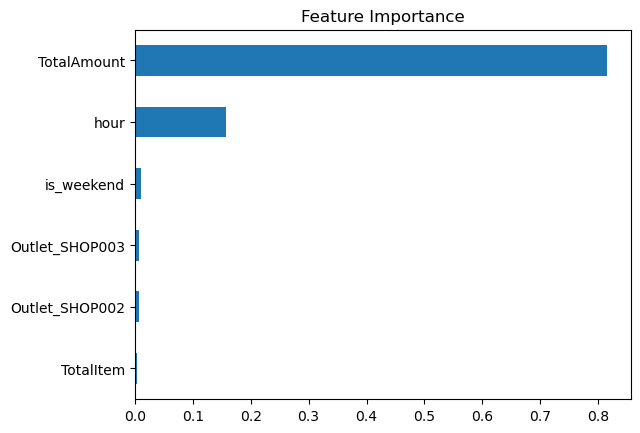

In [4]:
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
imp.plot(kind='barh')
plt.title('Feature Importance')
plt.show()